In [ ]:
import pandas as pd
import numpy as np
import torch
import datasets

import sys
import os
sys.path.insert(0, os.path.abspath("../.."))

from picpy.calibration import BinomialCalibrator, GaussianCalibrator
from picpy import LinearRegression, LogisticRegression
from picpy.penalties import L1Penalty, SCADPenalty, MCPPenalty
from picpy.selection import StabilitySelection, RecursiveSelection

In [ ]:
ds = datasets.load_from_disk("data/pile_data_source")
labels = np.load("cached_activations/pythia-70m/pile_data_source/labels.npy", allow_pickle=True)
print(labels.shape)

def load_layer(model, l):
    return np.load(f"cached_activations/{model}/pile_data_source/{l}.mean.npy").astype(np.float32)

In [ ]:
import os, time, pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import f1_score

MODEL, DS, MAX_ITER, SEED = "pythia-70m", "pile_data_source", 10, 0
OUT = f"results/{MODEL}/{DS}"
os.makedirs(OUT, exist_ok=True)

labels = np.load(f"cached_activations/{MODEL}/{DS}/labels.npy", allow_pickle=True)
idx_tr, idx_te = train_test_split(np.arange(len(labels)), test_size=0.3,
                                  stratify=labels, random_state=SEED)
np.savez(f"{OUT}/split.npz", idx_tr=idx_tr, idx_te=idx_te)   # même split pour toutes les méthodes

def f1_on(S, Xtr, ytr, Xte, yte):
    S = np.atleast_1d(S)
    if len(S) == 0:
        return np.nan
    m = SkLogReg(class_weight="balanced", max_iter=1000).fit(Xtr[:, S], ytr)
    return f1_score(yte, m.predict(Xte[:, S]))

results = []
for l in range(6):
    X = load_layer(MODEL, l)
    mu, sd = X[idx_tr].mean(0), np.maximum(X[idx_tr].std(0), 1e-3)   # stats du train seulement
    Xtr, Xte = (X[idx_tr] - mu) / sd, (X[idx_te] - mu) / sd
    Xtr_gpu = torch.tensor(Xtr, device="cuda", dtype=torch.float64)

    for src in np.unique(labels):
        ytr = (labels[idx_tr] == src).astype(float)
        yte = (labels[idx_te] == src).astype(float)

        # baseline Gurnee k=1 sur le même split
        d = Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)
        top10 = np.argsort(-np.abs(d))[:10]
        f1_top = [f1_on(j, Xtr, ytr, Xte, yte) for j in top10]

        # ta boucle
        rec = RecursiveSelection(
            model=LogisticRegression(lambda_=0, penalty=SCADPenalty(), refit=False),
            calibrator=BinomialCalibrator(alpha=0.05, n_simu=2000),
            max_iter=MAX_ITER, progress=True,
        )
        t0 = time.time()
        rec.fit(Xtr_gpu, ytr)
        supports = [np.asarray(S, int) for S in rec.supports_]

        res = dict(
            layer=l, source=src, seed=SEED, max_iter=MAX_ITER,
            supports=supports,
            sizes=[len(S) for S in supports],
            f1_levels=[f1_on(S, Xtr, ytr, Xte, yte) for S in supports],
            hit_max_iter=len(supports) >= MAX_ITER,
            baseline_top10=top10, baseline_f1=f1_top,
            baseline_best=int(top10[np.nanargmax(f1_top)]),
            fit_seconds=time.time() - t0,
            extra={k: getattr(rec, k) for k in ("lambdas_", "coefs_", "n_iter_") if hasattr(rec, k)},
        )
        results.append(res)
        print(f"L{l} {src}: K={len(supports)}{' (max_iter)' if res['hit_max_iter'] else ''} "
              f"| sizes={res['sizes']} | F1={np.round(res['f1_levels'], 3)} "
              f"| baseline k=1 F1={np.nanmax(f1_top):.3f}")

        with open(f"{OUT}/pic_loop_{src}.pkl", "wb") as f:
            pickle.dump([r for r in results if r["source"] == src], f)

## Similarité des sélections entre classes (pile_data_source)

Trois mesures par paire de classes : neurones en commun (Jaccard), similarité douce (corrélation max entre neurones), accord de signe. Changer `DS` pour `europarl_lang` si besoin.

### Cellule 1 : calcul des similarités

In [48]:
import glob, pickle, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

MODEL, DS = "pythia-70m", "pile_data_source"
LEVELS = [4]      # None = union de tous les niveaux ; sinon ex. [1] ou [1, 2]

R = {}
for f in sorted(glob.glob(f"results/{MODEL}/{DS}/pic_loop_*.pkl")):
    for r in pickle.load(open(f, "rb")):
        R[(str(r.get("source", r.get("language"))), r["layer"])] = r
classes = sorted({k[0] for k in R})
layers = sorted({k[1] for k in R})

labels = np.load(f"cached_activations/{MODEL}/{DS}/labels.npy", allow_pickle=True).astype(str)
idx_tr = np.load(f"results/{MODEL}/{DS}/split.npz")["idx_tr"]


def support(c, l, levels=LEVELS):
    S = R[(c, l)]["supports"]
    keep = range(len(S)) if levels is None else [t - 1 for t in levels if t <= len(S)]
    return np.unique(np.concatenate([np.asarray(S[t], int) for t in keep]))


def cohen_d(X, y):
    m1, m0 = X[y].mean(0), X[~y].mean(0)
    return (m1 - m0) / np.sqrt(0.5 * (X[y].var(0) + X[~y].var(0)) + 1e-8)


def similarity_matrices(l, levels=LEVELS):
    """Trois mesures de similarité entre les sélections de deux classes, pour une couche."""
    X = np.load(f"cached_activations/{MODEL}/{DS}/{l}.mean.npy").astype(np.float32)[idx_tr]
    X = (X - X.mean(0)) / np.maximum(X.std(0), 1e-3)
    S = {c: support(c, l, levels) for c in classes}
    D = {c: cohen_d(X, labels[idx_tr] == c) for c in classes}
    C = np.corrcoef(X.T)                              # corrélation entre neurones (2048 x 2048)
    C = np.nan_to_num(C)
    n = len(classes)
    jac, soft, sign = (np.full((n, n), np.nan) for _ in range(3))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            A, B = S[a], S[b]
            jac[i, j] = len(np.intersect1d(A, B)) / len(np.union1d(A, B))
            # Jaccard "doux" : chaque neurone de A est apparié au neurone de B le plus corrélé
            c = np.abs(C[np.ix_(A, B)])
            soft[i, j] = 0.5 * (c.max(1).mean() + c.max(0).mean())
            # les neurones choisis pour a varient-ils dans le même sens pour b ?
            if i != j:
                sign[i, j] = np.mean(np.sign(D[b][A]) == np.sign(D[a][A]))
    return dict(jaccard=jac, soft=soft, sign=sign)


SIM = {l: similarity_matrices(l) for l in layers}
print("ok :", len(classes), "classes,", len(layers), "couches")

ok : 8 classes, 6 couches


### Cellule 2 : heatmaps pour une couche

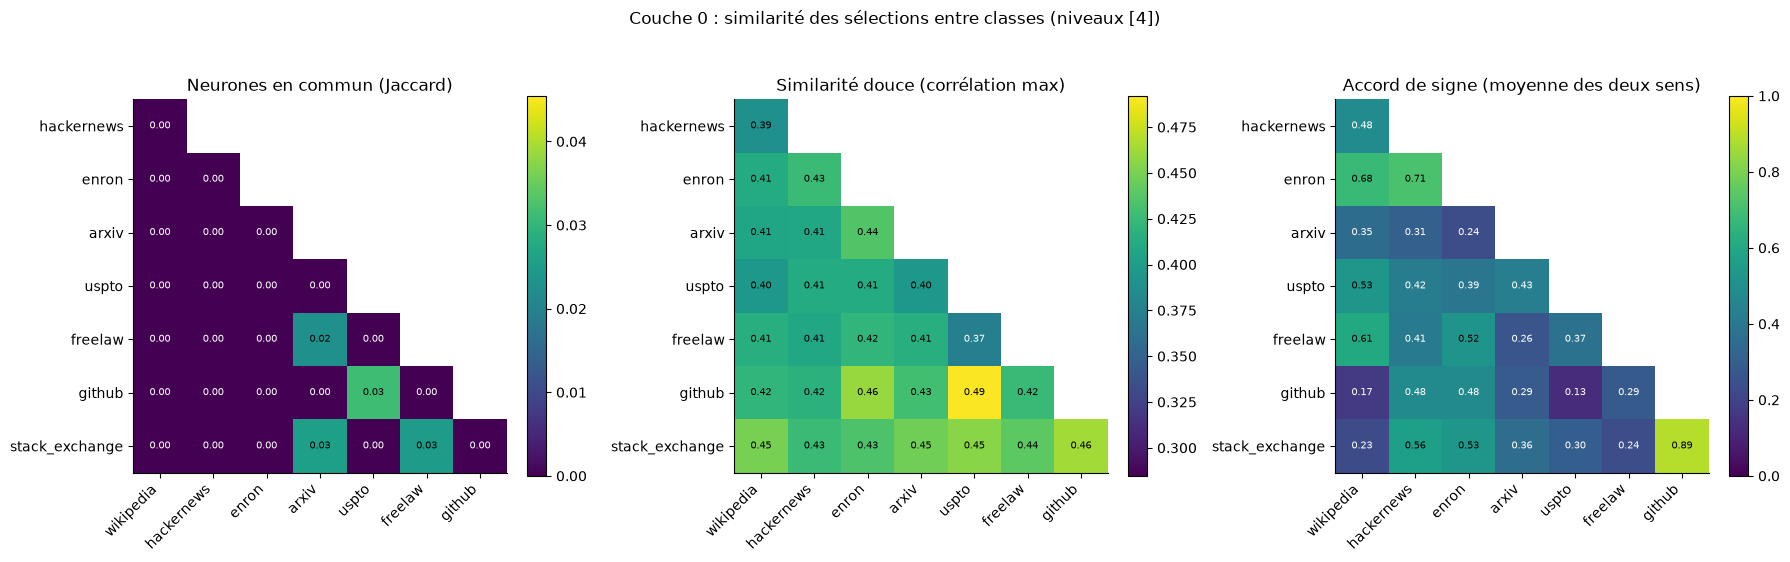

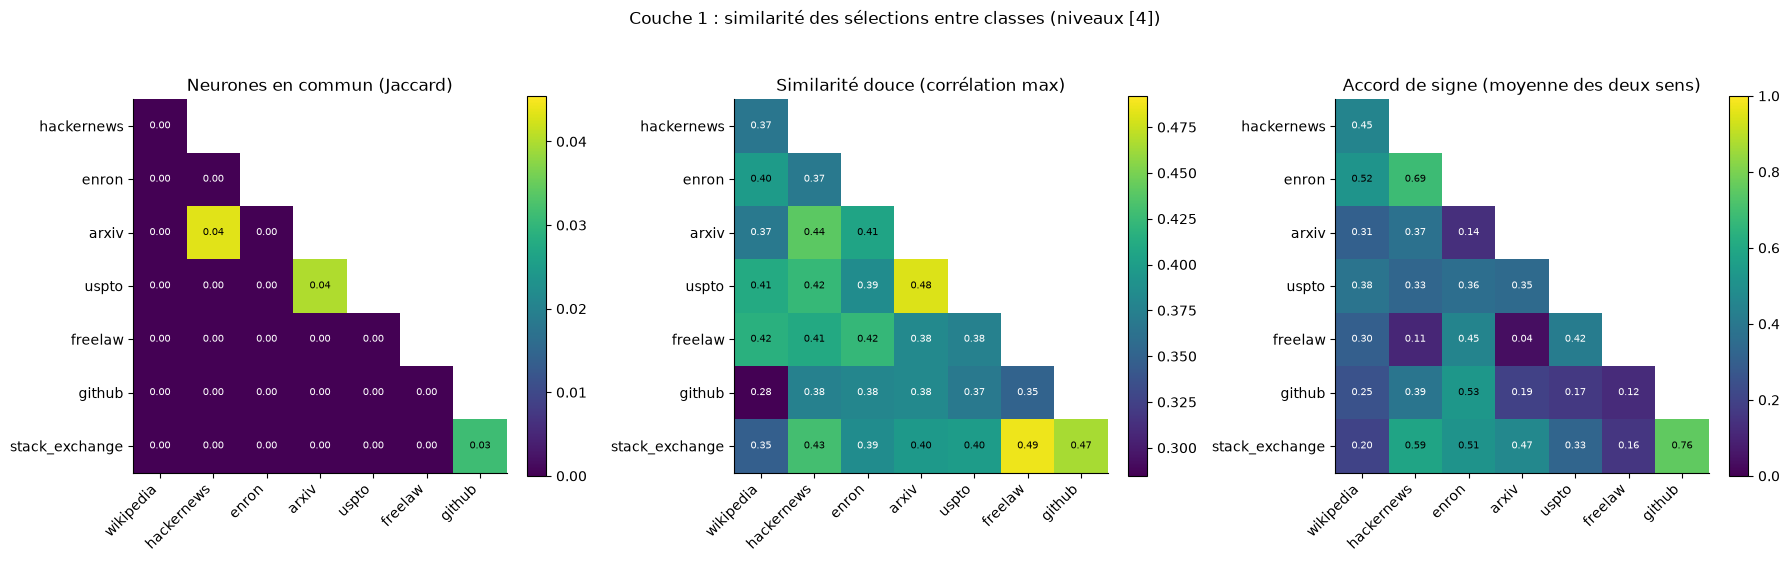

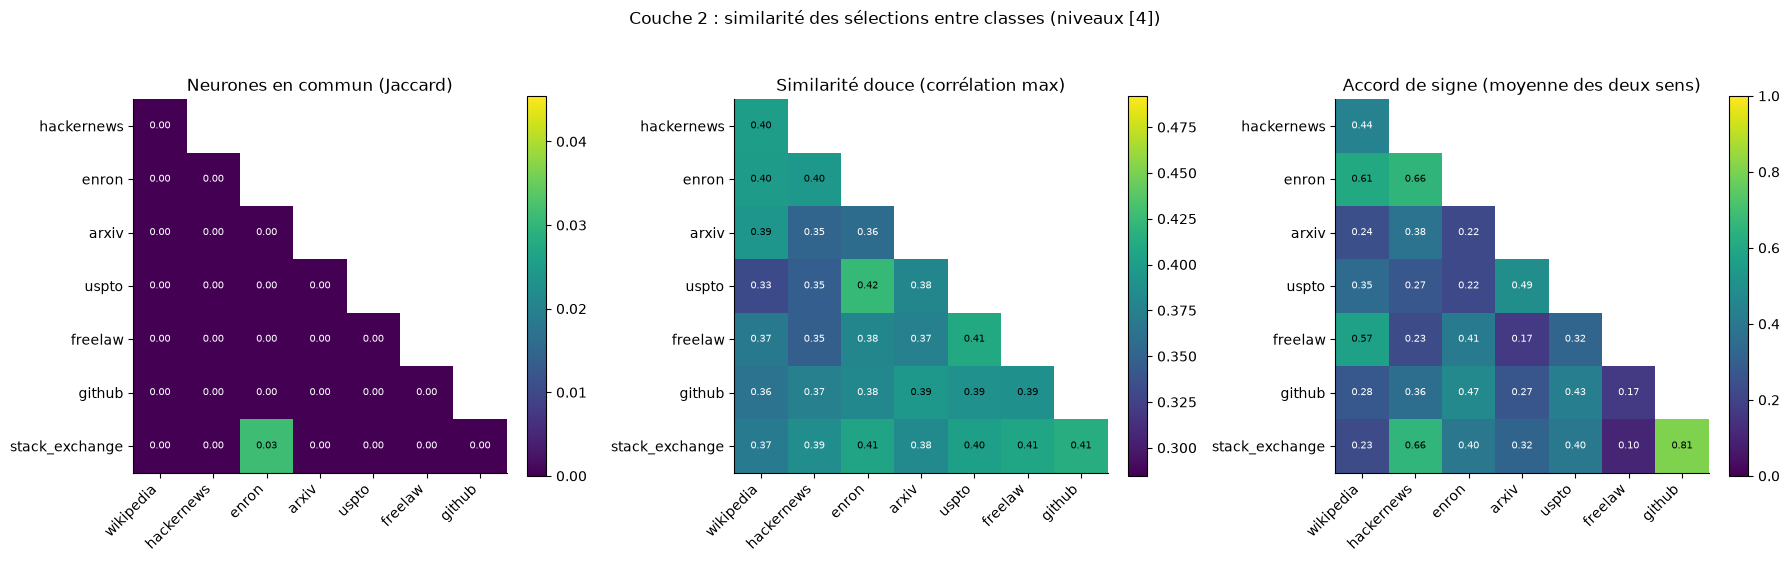

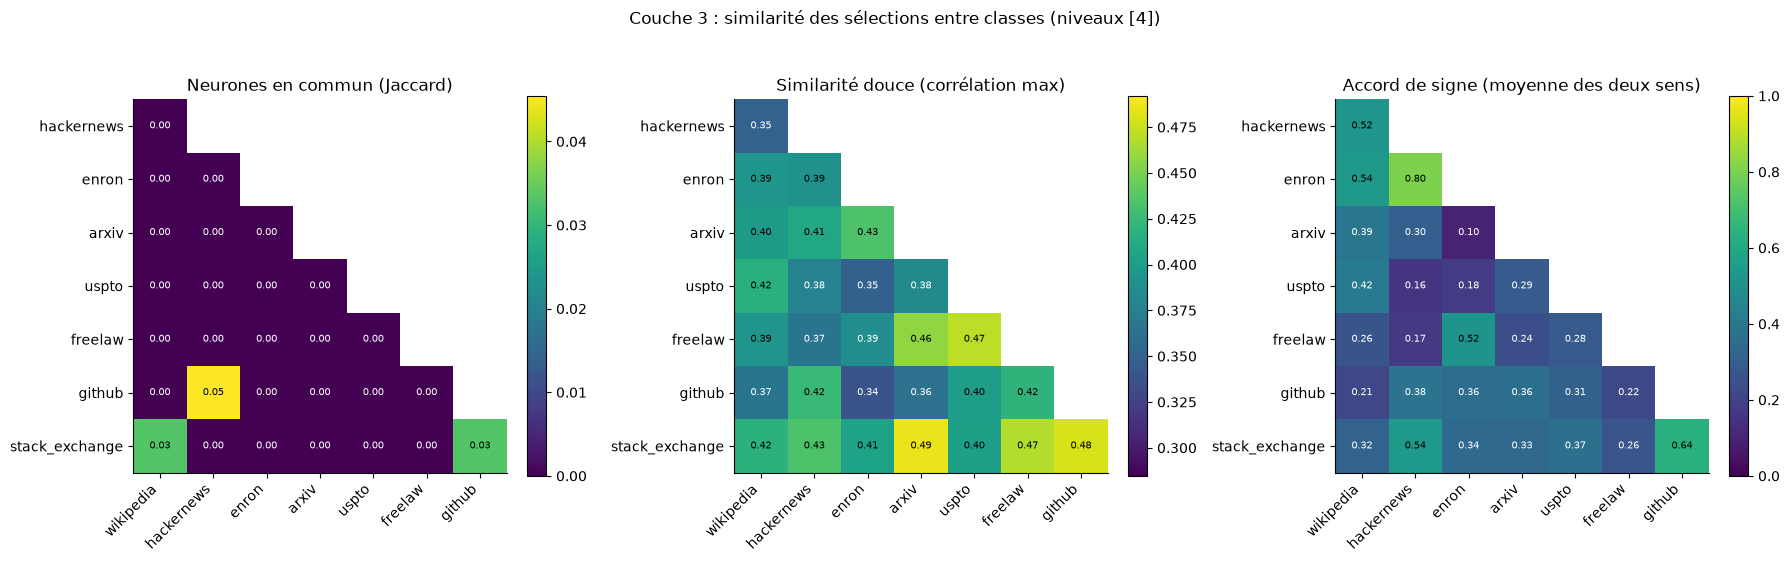

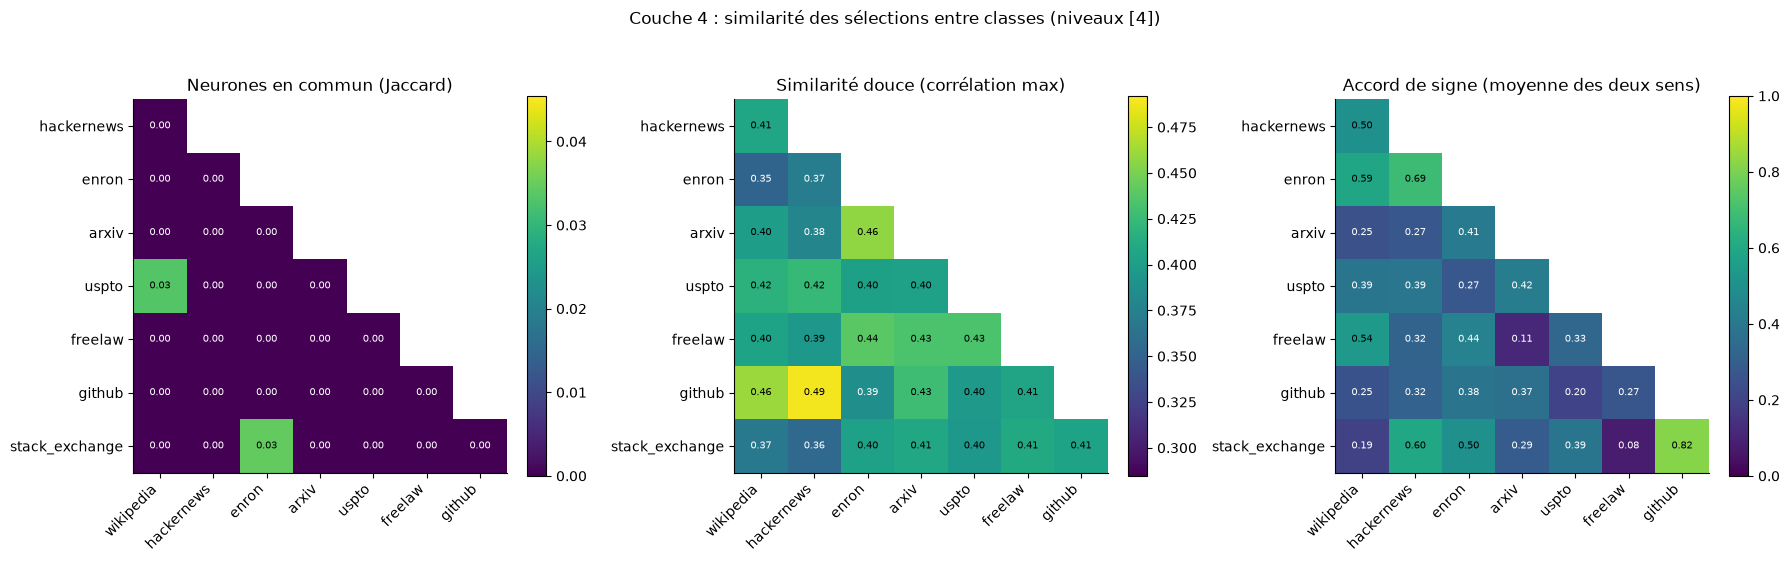

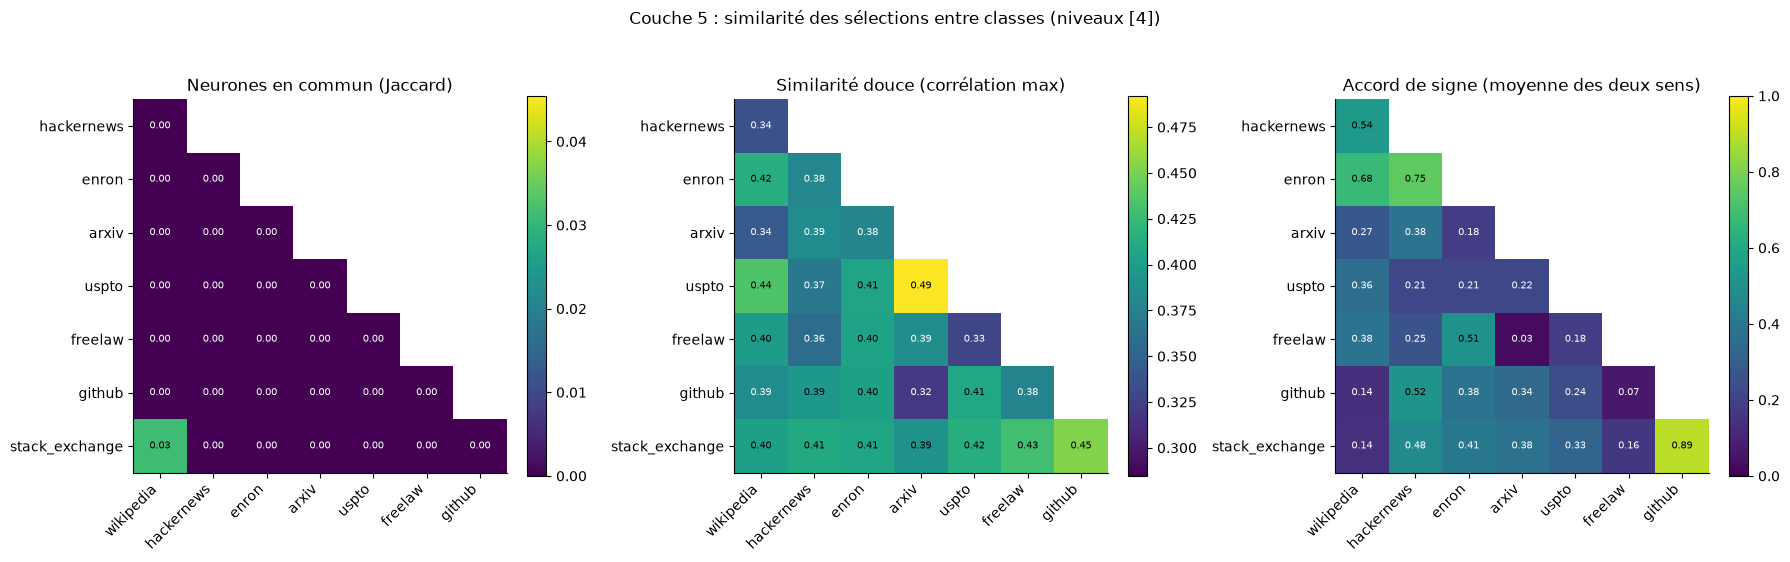

In [49]:
def symmetrize(A):
    B = A.T
    both = ~np.isnan(A) & ~np.isnan(B)
    return np.where(both, (A + B) / 2, np.where(np.isnan(A), B, A))

def global_order(sim=SIM):
    """Ordre unique des classes : clustering sur la similarité douce moyennée sur les couches."""
    S = np.mean([symmetrize(sim[l]["soft"]) for l in sim], axis=0)
    dist = 1 - np.nan_to_num(S, nan=0.0)
    np.fill_diagonal(dist, 0)
    return leaves_list(linkage(squareform(dist, checks=False), "average"))


KEYS = ["jaccard", "soft", "sign"]
ORDER = global_order()


def global_ranges(sim=SIM):
    """Échelle de couleur commune à toutes les couches, pour chaque mesure."""
    out = {}
    tri = np.tril_indices(len(classes), -1)
    for key in KEYS:
        vals = np.concatenate([symmetrize(sim[l][key])[tri] for l in sim])
        out[key] = (np.nanmin(vals), np.nanmax(vals))
    out["sign"] = (0, 1)
    return out


RANGES = global_ranges()


def plot_pair_heatmaps(l, sim=SIM, order=ORDER, ranges=RANGES):
    M = sim[l]
    names = [classes[i] for i in order]
    n = len(names)
    upper = np.triu(np.ones((n, n), dtype=bool))          # diagonale + triangle supérieur
    titles = {"jaccard": "Neurones en commun (Jaccard)",
              "soft": "Similarité douce (corrélation max)",
              "sign": "Accord de signe (moyenne des deux sens)"}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    for ax, key in zip(axes, KEYS):
        A = symmetrize(M[key])[np.ix_(order, order)]
        A = np.where(upper, np.nan, A)
        vmin, vmax = ranges[key]
        im = ax.imshow(A, cmap="viridis", vmin=vmin, vmax=vmax)
        mid = (vmin + vmax) / 2
        for i in range(n):
            for j in range(i):
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if A[i, j] < mid else "black")
        ax.set_xticks(range(n - 1), names[:-1], rotation=45, ha="right")
        ax.set_yticks(range(1, n), names[1:])
        ax.set_xlim(-0.5, n - 1.5)
        ax.set_ylim(n - 0.5, 0.5)
        ax.set_title(titles[key])
        ax.spines[["top", "right"]].set_visible(False)
        plt.colorbar(im, ax=ax, fraction=0.046)
    lv = "tous les niveaux" if LEVELS is None else f"niveaux {LEVELS}"
    fig.suptitle(f"Couche {l} : similarité des sélections entre classes ({lv})", y=1.02)
    plt.tight_layout()
    plt.show()


for layer in layers:
    plot_pair_heatmaps(layer)

### Cellule 3 : top des paires, toutes couches

jaccard   soft   sign
a          b                                    
github     stack_exchange    0.017  0.459  0.750
hackernews stack_exchange    0.019  0.458  0.586
freelaw    stack_exchange    0.004  0.422  0.103
           github            0.000  0.419  0.163
arxiv      uspto             0.015  0.415  0.321
           freelaw           0.000  0.414  0.129
github     uspto             0.008  0.412  0.254
           hackernews        0.000  0.397  0.342
arxiv      github            0.006  0.396  0.281
           enron             0.000  0.396  0.226

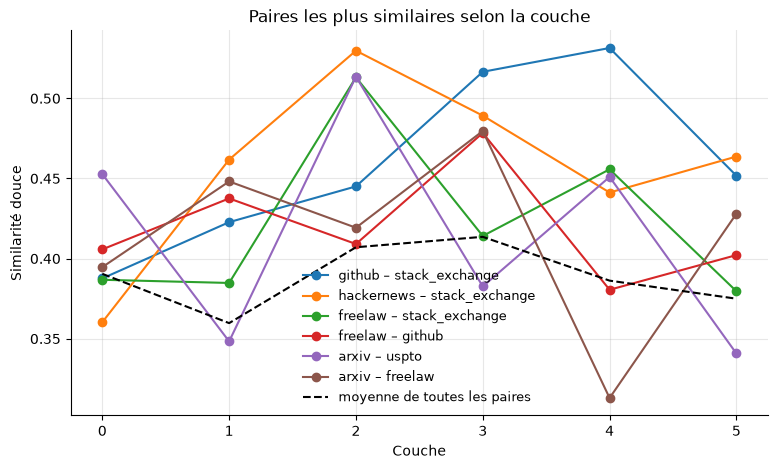

In [44]:
rows = []
for l in layers:
    for i, j in itertools.combinations(range(len(classes)), 2):
        rows.append(dict(layer=l, a=classes[i], b=classes[j],
                         jaccard=SIM[l]["jaccard"][i, j],
                         soft=SIM[l]["soft"][i, j],
                         sign=np.nanmean([SIM[l]["sign"][i, j], SIM[l]["sign"][j, i]])))
pairs = pd.DataFrame(rows)
summary = (pairs.groupby(["a", "b"])[["jaccard", "soft", "sign"]].mean()
           .sort_values("soft", ascending=False).round(3))
display(summary.head(10))

fig, ax = plt.subplots(figsize=(9, 5))
top = summary.head(6).index
for a, b in top:
    g = pairs[(pairs.a == a) & (pairs.b == b)].sort_values("layer")
    ax.plot(g.layer, g.soft, marker="o", label=f"{a} – {b}")
base = pairs.groupby("layer").soft.mean()
ax.plot(base.index, base.values, "k--", label="moyenne de toutes les paires")
ax.set_xlabel("Couche"); ax.set_ylabel("Similarité douce")
ax.set_title("Paires les plus similaires selon la couche")
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Cellule 4 : la similarité change-t-elle avec le niveau ?

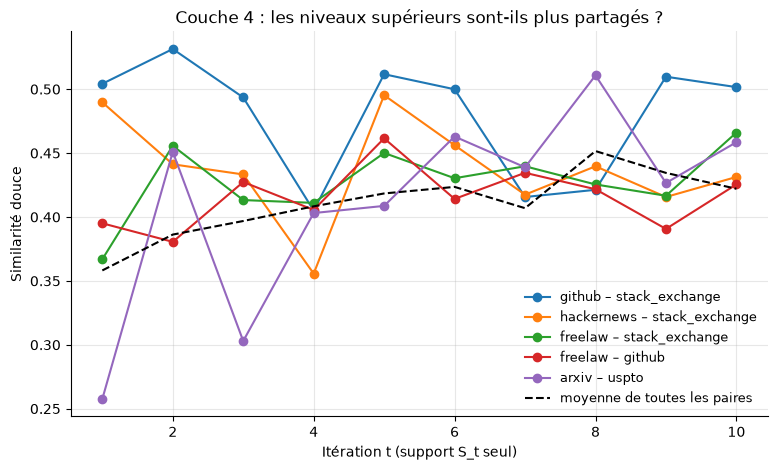

In [45]:
def soft_by_level(l, max_t=10):
    out = []
    for t in range(1, max_t + 1):
        M = similarity_matrices(l, levels=[t])["soft"]
        iu = np.triu_indices(len(classes), 1)
        for (i, j) in zip(*iu):
            out.append(dict(t=t, a=classes[i], b=classes[j], soft=M[i, j]))
    return pd.DataFrame(out)


L_SEL = 4
lev = soft_by_level(L_SEL)
fig, ax = plt.subplots(figsize=(9, 5))
for (a, b) in summary.head(5).index:
    g = lev[(lev.a == a) & (lev.b == b)]
    ax.plot(g.t, g.soft, marker="o", label=f"{a} – {b}")
m = lev.groupby("t").soft.mean()
ax.plot(m.index, m.values, "k--", label="moyenne de toutes les paires")
ax.set_xlabel("Itération t (support S_t seul)"); ax.set_ylabel("Similarité douce")
ax.set_title(f"Couche {L_SEL} : les niveaux supérieurs sont-ils plus partagés ?")
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Le partage entre classes proches dépend-il du niveau ?

**Question.** Deux classes proches (par exemple `github` et `stack_exchange`) partagent-elles davantage leur encodage aux premiers niveaux de la boucle (S₁, S₂) qu'aux niveaux suivants ?

**Pourquoi corriger la similarité douce.** La similarité douce brute augmente mécaniquement avec le niveau, parce que les supports grossissent : plus un ensemble contient de neurones, plus il est facile d'y trouver un neurone corrélé à un neurone de l'autre ensemble. On la compare donc à une **référence aléatoire** :

- on remplace le support de B par des ensembles de neurones tirés au hasard, de même taille, et on recalcule la similarité avec A (et symétriquement pour B) ;
- on répète `N_NULL` fois, puis on calcule le **z-score** : $z = \dfrac{\text{sim}(S_t^A, S_t^B) - \text{moyenne}_{\text{aléatoire}}}{\text{écart type}_{\text{aléatoire}}}$.

Un z autour de 0 signifie « pas plus similaire que le hasard » ; un z supérieur à 2 signale une similarité nettement au-dessus du hasard.

**Accord de signe.** Pour chaque niveau, on mesure aussi la part des neurones choisis pour A qui varient dans le même sens pour B (moyenne des deux sens). Autour de 0,5, c'est le hasard ; au-dessus, les deux classes activent ces neurones de la même façon ; en dessous, ces neurones servent à les distinguer.

**Paires proches.** `CLOSE_PAIRS` est fixé **à l'avance**, à partir de la nature des sources (code et forums, textes techniques, textes juridiques). Les définir à partir des résultats rendrait la comparaison circulaire.

**Ce qu'on regarde.**
1. L'écart de z entre paires proches et autres paires, niveau par niveau : est-il plus grand en S₁ et S₂ qu'aux niveaux suivants ?
2. Les trajectoires des paires les plus similaires en S₁.
3. Une heatmap paires × niveaux du z, pour voir où se concentre le partage.

Le calcul prend quelques minutes (6 couches × 10 niveaux × 28 paires × `N_NULL` tirages).

In [50]:
import warnings
from scipy.stats import spearmanr

N_NULL = 50
MAX_T = 10
CLOSE_PAIRS = {frozenset(p) for p in [
    ("github", "stack_exchange"), ("hackernews", "stack_exchange"),
    ("arxiv", "uspto"), ("freelaw", "uspto"), ("arxiv", "wikipedia"),
]}
rng = np.random.default_rng(0)


def soft_sim(C, A, B):
    """Similarité douce : chaque neurone d'un ensemble est apparié au plus corrélé de l'autre."""
    c = C[np.ix_(A, B)]
    return 0.5 * (c.max(1).mean() + c.max(0).mean())


rows = []
for l in layers:
    X = np.load(f"cached_activations/{MODEL}/{DS}/{l}.mean.npy").astype(np.float32)[idx_tr]
    X = (X - X.mean(0)) / np.maximum(X.std(0), 1e-3)
    with np.errstate(divide="ignore", invalid="ignore"):
        C = np.abs(np.nan_to_num(np.corrcoef(X.T)))
    np.fill_diagonal(C, 1.0)
    p = X.shape[1]
    D = {c: cohen_d(X, labels[idx_tr] == c) for c in classes}

    for t in range(1, MAX_T + 1):
        S = {c: np.asarray(R[(c, l)]["supports"][t - 1], int)
             for c in classes if len(R[(c, l)]["supports"]) >= t}
        for a, b in itertools.combinations(sorted(S), 2):
            A, B = S[a], S[b]
            sim = soft_sim(C, A, B)
            null = [0.5 * (soft_sim(C, A, rng.choice(p, len(B), replace=False))
                           + soft_sim(C, rng.choice(p, len(A), replace=False), B))
                    for _ in range(N_NULL)]
            sign = 0.5 * (np.mean(np.sign(D[b][A]) == np.sign(D[a][A]))
                          + np.mean(np.sign(D[a][B]) == np.sign(D[b][B])))
            rows.append(dict(layer=l, t=t, a=a, b=b, close=frozenset((a, b)) in CLOSE_PAIRS,
                             soft=sim, null_mean=np.mean(null),
                             soft_z=(sim - np.mean(null)) / np.std(null), sign=sign))
    print(f"couche {l} terminée")

levels_pairs = pd.DataFrame(rows)
levels_pairs.to_csv(f"results/{MODEL}/{DS}/pair_similarity_by_level.csv", index=False)

# Tableau récapitulatif : moyennes sur les couches
recap = levels_pairs.groupby("t").agg(soft_brut=("soft", "mean"), reference=("null_mean", "mean"))
for m in ["soft_z", "sign"]:
    g = levels_pairs.groupby(["t", "close"])[m].mean().unstack()
    recap[f"{m}_proches"] = g[True]
    recap[f"{m}_autres"] = g[False]
    recap[f"{m}_ecart"] = g[True] - g[False]
display(recap.round(3))

# Le classement des paires est-il stable d'un niveau à l'autre ?
base = levels_pairs[levels_pairs.t == 1].groupby(["a", "b"])[["soft_z", "sign"]].mean()
for t in [2, 3, 5, MAX_T]:
    cur = levels_pairs[levels_pairs.t == t].groupby(["a", "b"])[["soft_z", "sign"]].mean()
    print(f"Corrélation de rang S1 vs S{t} : z = {spearmanr(base.soft_z, cur.soft_z)[0]:.2f}, "
          f"signe = {spearmanr(base.sign, cur.sign)[0]:.2f}")

couche 0 terminée
couche 1 terminée
couche 2 terminée
couche 3 terminée
couche 4 terminée
couche 5 terminée


,soft_brut,reference,soft_z_proches,soft_z_autres,soft_z_ecart,sign_proches,sign_autres,sign_ecart
t,,,,,,,,
1,0.350,0.385,0.131,-1.260,1.391,0.440,0.289,0.152
2,0.389,0.408,0.281,-0.852,1.133,0.455,0.329,0.126
3,0.388,0.412,-0.641,-1.001,0.360,0.470,0.332,0.138
4,0.402,0.419,-0.462,-0.778,0.315,0.472,0.347,0.125
5,0.409,0.423,-0.075,-0.675,0.600,0.493,0.347,0.146
6,0.412,0.425,-0.376,-0.721,0.345,0.490,0.366,0.124
7,0.412,0.425,-0.374,-0.753,0.379,0.497,0.370,0.127
8,0.421,0.432,-0.203,-0.635,0.432,0.494,0.372,0.122
9,0.420,0.428,-0.340,-0.407,0.067,0.511,0.386,0.125


Corrélation de rang S1 vs S2 : z = 0.22, signe = 0.96
Corrélation de rang S1 vs S3 : z = 0.36, signe = 0.93
Corrélation de rang S1 vs S5 : z = 0.53, signe = 0.92
Corrélation de rang S1 vs S10 : z = 0.18, signe = 0.89


### Figures

- **À gauche** : le z moyen des paires proches et des autres paires selon le niveau. Si le partage est concentré dans le premier ordre, l'écart entre les deux courbes est maximal en S₁–S₂ puis se réduit.
- **Au centre** : l'accord de signe moyen, même lecture.
- **À droite** : les trajectoires des paires les plus similaires en S₁. Des valeurs au-dessus de la ligne z = 2 signalent une similarité nettement supérieure au hasard.

La heatmap qui suit donne le z de chaque paire à chaque niveau (moyenne sur les couches), les paires étant triées par leur z en S₁.

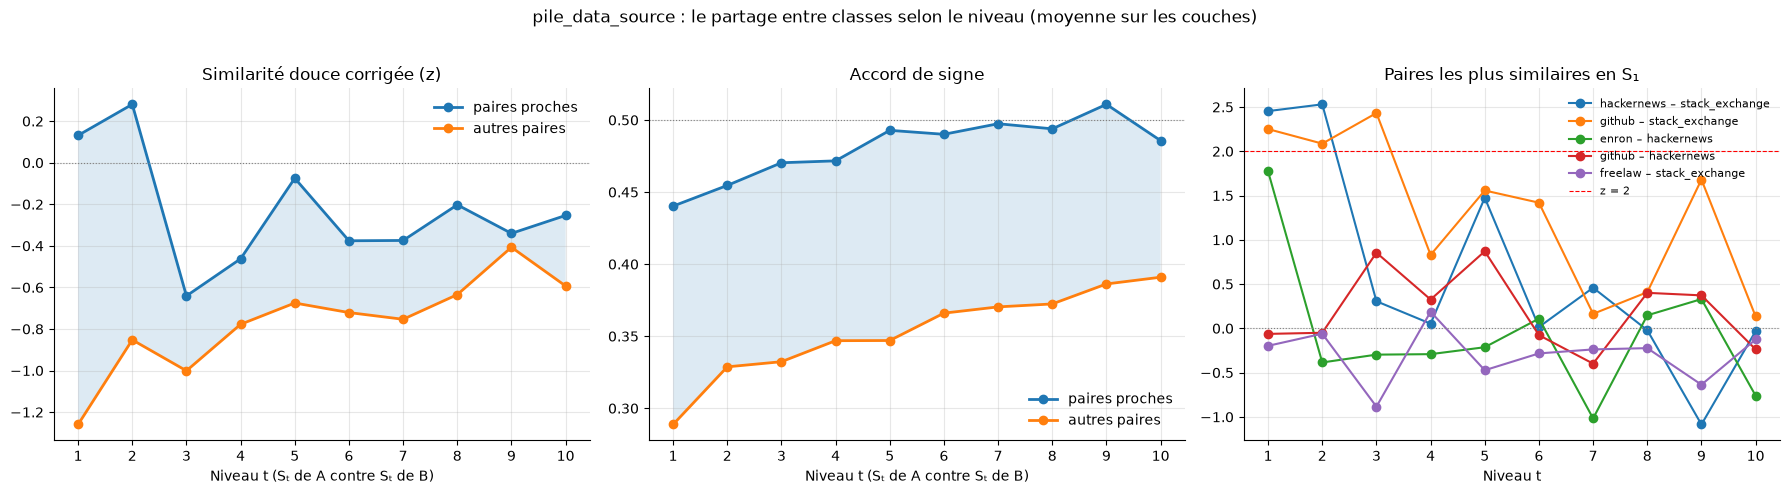

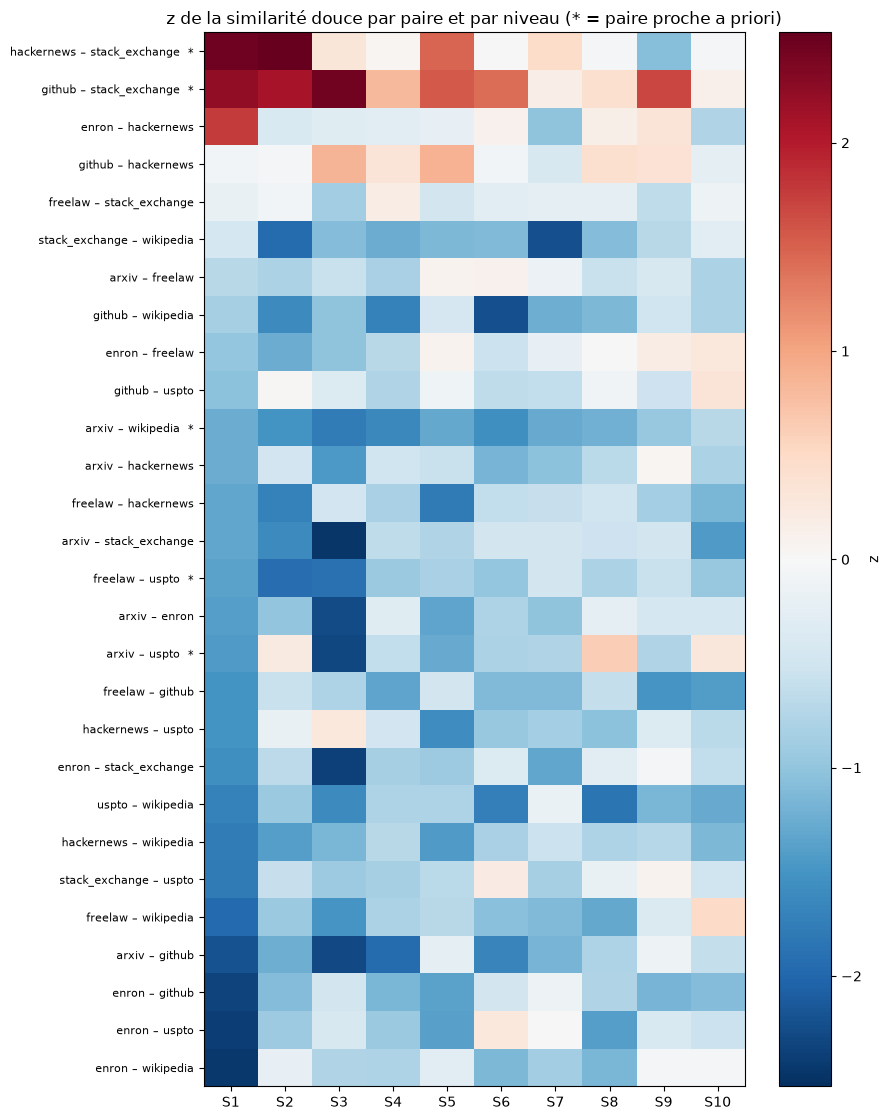

In [51]:
t_vals = sorted(levels_pairs.t.unique())
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

for ax, m, title in [(axes[0], "soft_z", "Similarité douce corrigée (z)"),
                     (axes[1], "sign", "Accord de signe")]:
    g = levels_pairs.groupby(["t", "close"])[m].mean().unstack()
    ax.plot(g.index, g[True], marker="o", lw=2, label="paires proches")
    ax.plot(g.index, g[False], marker="o", lw=2, label="autres paires")
    ax.fill_between(g.index, g[False], g[True], alpha=0.15)
    if m == "soft_z":
        ax.axhline(0, color="gray", lw=0.8, ls=":")
    else:
        ax.axhline(0.5, color="gray", lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("Niveau t (Sₜ de A contre Sₜ de B)")
    ax.set_xticks(t_vals); ax.legend(frameon=False); ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

pair_t = levels_pairs.groupby(["a", "b", "t"]).soft_z.mean().unstack()
top = pair_t.sort_values(1, ascending=False).head(5)
for (a, b), row in top.iterrows():
    axes[2].plot(row.index, row.values, marker="o", label=f"{a} – {b}")
axes[2].axhline(2, color="red", lw=0.8, ls="--", label="z = 2")
axes[2].axhline(0, color="gray", lw=0.8, ls=":")
axes[2].set_title("Paires les plus similaires en S₁")
axes[2].set_xlabel("Niveau t"); axes[2].set_xticks(t_vals)
axes[2].legend(frameon=False, fontsize=8); axes[2].grid(alpha=0.3)
axes[2].spines[["top", "right"]].set_visible(False)
fig.suptitle(f"{DS} : le partage entre classes selon le niveau (moyenne sur les couches)", y=1.02)
plt.tight_layout()
plt.show()

# Heatmap paires x niveaux
H = pair_t.sort_values(1, ascending=False)
lim = np.nanmax(np.abs(H.values))
fig, ax = plt.subplots(figsize=(9, 0.35 * len(H) + 1.5))
im = ax.imshow(H.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(H.shape[1]), [f"S{t}" for t in H.columns])
ax.set_yticks(range(len(H)), [f"{a} – {b}" + ("  *" if frozenset((a, b)) in CLOSE_PAIRS else "")
                              for a, b in H.index], fontsize=8)
ax.set_title("z de la similarité douce par paire et par niveau (* = paire proche a priori)")
plt.colorbar(im, ax=ax, label="z")
plt.tight_layout()
plt.show()

### Lecture et limites

**Lecture attendue.** Si le partage sémantique est porté par le premier ordre, on doit voir : un écart de z entre paires proches et autres maximal en S₁–S₂, des paires proches nettement au-dessus du hasard (z > 2) aux premiers niveaux, puis un retour vers 0 aux niveaux supérieurs.

**Résultats sur `pile_data_source` (analyse du 18/11).** C'est ce qu'on observe. L'écart de z vaut environ 1,4 en S₁ et 1,1 en S₂, puis 0,3 à 0,6 de S₃ à S₈ et moins de 0,4 en S₉–S₁₀. `hackernews – stack_exchange` et `github – stack_exchange` dépassent z = 2 en S₁–S₂, puis reviennent vers 0 en S₁₀. La similarité douce brute, elle, augmente avec le niveau, mais la référence aléatoire augmente presque autant : cette hausse est un effet de la taille des supports.

**Interprétation.** La proximité entre classes est encodée dans le premier ordre. Les ordres supérieurs sont moins spécifiques à leur classe, mais pas plus partagés entre classes proches.

**Limites.**
- Peu de paires : 8 classes, 5 paires proches.
- `CLOSE_PAIRS` est défini à la main ; un critère externe (par exemple la similarité lexicale des textes) serait plus solide.
- Un seul split et `N_NULL` tirages, sans intervalle de confiance : un bootstrap sur les séquences dirait si la baisse entre S₂ et S₃ est significative.
- À vérifier sur `europarl_lang`, avec les familles de langues comme paires proches.

## Analyse causale : le modèle utilise-t-il les ordres supérieurs ?

Jusqu'ici, la boucle montre que S₁, S₂, … **prédisent** la classe. Cela ne dit pas si le modèle **s'en sert**. On le teste par **ablation** : on fixe l'activation de certains neurones d'une couche pendant le passage avant, puis on mesure la hausse de la perte de modélisation du langage (entropie croisée sur le prochain token), séquence par séquence. C'est la méthode de Gurnee et al. pour leurs neurones de contexte (figure 3, panneau de droite).

**Conditions comparées**, pour chaque classe `c` et chaque couche de `ABL_LAYERS` :

| Condition | Neurones ablatés |
|---|---|
| `S1` | le premier support |
| `S2` | le deuxième support seul |
| `S1+S2` | l'union des deux |
| `S1..S5` | l'union des cinq premiers supports |
| `S1..all` | l'union de tous les supports |
| `rand(...)` | des neurones tirés au hasard, de même taille, hors des supports de `c` |

**Mesures.** Pour chaque condition : la hausse relative de la perte sur les séquences de la classe `c` (« cible ») et sur les séquences des autres classes (« autres »). La **spécificité** est la différence cible moins autres.

**Hypothèses.**
- **H1, effet réel** : ablater S₁ dégrade la classe cible nettement plus que des neurones aléatoires de même taille.
- **H2, spécificité** : l'effet porte sur la classe cible, pas sur les autres.
- **H3, voies de secours** : si S₂ est un encodage de secours, ablater S₂ seul a peu d'effet, mais ablater S₁ ∪ S₂ dégrade **plus** que S₁ seul. On le résume par l'**interaction** `Δ(S1+S2) − Δ(S1) − Δ(S2)` : positive, les deux supports se compensent (redondance) ; nulle, les effets s'additionnent ; négative, ils se recouvrent.

**Réglages.**
- `ABLATION = "mean"` remplace l'activation par sa moyenne sur le train, ce qui perturbe moins le modèle qu'une mise à zéro (`"zero"`, le choix de Gurnee et al.).
- `N_PER_CLASS` séquences de test par classe. Le temps de calcul est proportionnel à `N_PER_CLASS × nombre de classes × nombre de conditions × len(ABL_LAYERS)`. Sur GPU, compter quelques minutes avec les valeurs par défaut ; sur CPU, baisser `N_PER_CLASS` pour un premier essai.

Les cellules utilisent `R`, `classes`, `labels`, `idx_tr`, `MODEL` et `DS` définis plus haut.

In [52]:
import torch
import torch.nn.functional as F
import datasets
from transformers import AutoModelForCausalLM, AutoTokenizer

ABL_LAYERS = [3, 4]
ABLATION = "mean"          # "mean" ou "zero"
N_PER_CLASS = 30
BATCH = 8
SEED = 0

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_grad_enabled(False)
lm = AutoModelForCausalLM.from_pretrained(f"EleutherAI/{MODEL}").to(device).eval()
tok = AutoTokenizer.from_pretrained(f"EleutherAI/{MODEL}")
blocks = lm.gpt_neox.layers

data_tok = datasets.load_from_disk(f"data/{DS}").with_format("numpy")[:]
TOKENS = torch.from_numpy(np.stack(data_tok["tokens"])).long()
label_key = "language" if "language" in data_tok else "distribution"
assert len(TOKENS) == len(labels) and np.all(np.asarray(data_tok[label_key]).astype(str) == labels), \
    "Les tokens et labels.npy ne sont pas alignés (activations extraites sur un sous-échantillon ?)"

idx_te = np.load(f"results/{MODEL}/{DS}/split.npz")["idx_te"]
rng_abl = np.random.default_rng(SEED)
EVAL = {c: rng_abl.choice(idx_te[labels[idx_te] == c], min(N_PER_CLASS, (labels[idx_te] == c).sum()),
                          replace=False) for c in classes}
EVAL_IDX = np.concatenate([EVAL[c] for c in classes])
EVAL_LAB = labels[EVAL_IDX]
print(f"device = {device}, {len(EVAL_IDX)} séquences d'évaluation")


def seq_losses(layer=None, neurons=None, values=None):
    """Entropie croisée moyenne par séquence, avec ablation optionnelle de `neurons` dans `layer`."""
    handle = None
    if neurons is not None and len(neurons) > 0:
        idx_t = torch.as_tensor(np.asarray(neurons), device=device)
        val_t = torch.as_tensor(np.asarray(values), dtype=torch.float32, device=device)

        def hook(module, inp, out):
            out = out.clone()
            out[..., idx_t] = val_t.to(out.dtype)
            return out
        handle = blocks[layer].mlp.act.register_forward_hook(hook)
    out = []
    try:
        for s in range(0, len(EVAL_IDX), BATCH):
            x = TOKENS[EVAL_IDX[s:s + BATCH]].to(device)
            logits = lm(x).logits.float()
            ce = F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]), x[:, 1:].reshape(-1),
                                 reduction="none").view(x.shape[0], -1).mean(1)
            out.append(ce.cpu().numpy())
    finally:
        if handle is not None:
            handle.remove()
    return np.concatenate(out)


BASE_LOSS = seq_losses()
print("Perte de base par classe :",
      {c: round(float(BASE_LOSS[EVAL_LAB == c].mean()), 3) for c in classes})

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 3499.78it/s]
c:\Users\Utilisateur\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Utilisateur\.cache\huggingface\hub\models--EleutherAI--pythia-70m. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


device = cuda, 240 séquences d'évaluation
Perte de base par classe : {'arxiv': 2.6, 'enron': 3.309, 'freelaw': 2.877, 'github': 1.737, 'hackernews': 3.609, 'stack_exchange': 2.603, 'uspto': 3.132, 'wikipedia': 3.533}


In [53]:
def union(c, l, ts):
    S = R[(c, l)]["supports"]
    return np.unique(np.concatenate([np.asarray(S[t - 1], int) for t in ts if t <= len(S)]))


abl_rows = []
for l in ABL_LAYERS:
    X_l = np.load(f"cached_activations/{MODEL}/{DS}/{l}.mean.npy").astype(np.float32)
    mean_act = X_l[idx_tr].mean(0)          # activation moyenne de chaque neurone sur le train
    p = X_l.shape[1]
    for c in classes:
        n_sup = len(R[(c, l)]["supports"])
        conds = {"S1": union(c, l, [1]), "S2": union(c, l, [2]), "S1+S2": union(c, l, [1, 2]),
                 "S1..S5": union(c, l, range(1, 6)), "S1..all": union(c, l, range(1, n_sup + 1))}
        pool = np.setdiff1d(np.arange(p), conds["S1..all"])     # neurones jamais sélectionnés pour c
        for name in ["S1", "S1+S2", "S1..all"]:
            conds[f"rand({name})"] = rng_abl.choice(pool, min(len(conds[name]), len(pool)), replace=False)
        for name, neurons in conds.items():
            vals = mean_act[neurons] if ABLATION == "mean" else np.zeros(len(neurons))
            rel = (seq_losses(l, neurons, vals) - BASE_LOSS) / BASE_LOSS
            abl_rows.append(dict(layer=l, cls=c, cond=name, n_neurons=len(neurons),
                                 d_target=rel[EVAL_LAB == c].mean(),
                                 d_other=rel[EVAL_LAB != c].mean(),
                                 se_target=rel[EVAL_LAB == c].std() / np.sqrt((EVAL_LAB == c).sum())))
        print(f"couche {l}, {c} : fait")

ablation = pd.DataFrame(abl_rows)
ablation["specificity"] = ablation.d_target - ablation.d_other
ablation.to_csv(f"results/{MODEL}/{DS}/ablation_{ABLATION}.csv", index=False)

# Interaction S1/S2 : positive = les deux supports se compensent (voie de secours)
piv = ablation.pivot_table(index=["layer", "cls"], columns="cond", values="d_target")
piv["interaction"] = piv["S1+S2"] - piv["S1"] - piv["S2"]
display((100 * piv[["S1", "S2", "S1+S2", "interaction", "rand(S1+S2)", "S1..all", "rand(S1..all)"]]).round(2)
        .rename(columns=lambda s: s + " (%)"))

couche 3, arxiv : fait
couche 3, enron : fait
couche 3, freelaw : fait
couche 3, github : fait
couche 3, hackernews : fait
couche 3, stack_exchange : fait
couche 3, uspto : fait
couche 3, wikipedia : fait
couche 4, arxiv : fait
couche 4, enron : fait
couche 4, freelaw : fait
couche 4, github : fait
couche 4, hackernews : fait
couche 4, stack_exchange : fait
couche 4, uspto : fait
couche 4, wikipedia : fait


cond                  S1 (%)  S2 (%)  S1+S2 (%)  interaction (%)  rand(S1+S2) (%)  S1..all (%)  rand(S1..all) (%)
layer cls                                                                                                        
3     arxiv             0.04    0.10       0.08            -0.05             0.23         1.03               1.09
      enron             0.30   -0.03       0.49             0.22             0.18         1.76               0.72
      freelaw           0.14    0.36       0.62             0.12             0.26         1.96               1.58
      github            0.55    0.55       0.72            -0.38             0.49         4.80               3.02
      hackernews        0.16    0.14       0.16            -0.15            -0.02         0.70               0.60
      stack_exchange    0.13    0.05       0.29             0.11             0.36         1.74               1.45
      uspto             0.27    0.19       0.39            -0.07             0.13         1.35               0.65
      wikipedia         0.16    0.13       0.28            -0.01             0.09         1.29               0.71
4     arxiv             0.26    0.35       0.64             0.03             0.10         2.37               1.09
      enron             0.22    0.41       0.55            -0.08             0.22         1.91               1.35
      freelaw           1.22    0.49       1.66            -0.05             0.36         3.86               1.35
      github            0.98    1.26       1.86            -0.38             1.04         5.20               3.29
      hackernews        0.24    0.44       0.53            -0.16             0.29         1.81               0.55
      stack_exchange    0.45    0.17       0.68             0.07             0.25         2.46               1.93
      uspto             0.74    0.24       1.03             0.05             0.11         3.23               0.62
      wikipedia         0.20    0.11       0.28            -0.04             0.29         1.72               1.00

### Lecture des figures d'ablation

- **À gauche** : hausse relative de la perte sur la classe cible (barres pleines) et sur les autres classes (barres hachurées), moyennée sur les classes, pour chaque condition. Les barres d'erreur sont l'erreur standard entre classes.
  - **H1** : chaque support doit dépasser l'ablation aléatoire de même taille : `S1` contre `rand(S1)`, `S1+S2` contre `rand(S1+S2)`, `S1..all` contre `rand(S1..all)`.
  - **H2** : barres pleines au-dessus des barres hachurées.
- **À droite** : l'interaction S₁/S₂ par classe. Des points au-dessus de 0 indiquent que S₂ ne prend le relais que lorsque S₁ est retiré.

**Précautions.**
- L'ablation porte sur **une seule couche** : les couches suivantes peuvent reconstruire l'information, ce qui atténue tous les effets.
- La perte est moyennée sur toute la séquence, y compris sur des tokens où le contexte importe peu : les effets sont donc petits en valeur absolue (de l'ordre du pourcent), comme chez Gurnee et al. C'est la comparaison avec les ablations aléatoires qui compte.
- Avec `N_PER_CLASS = 30`, l'erreur standard par classe est notable : regarder la tendance sur l'ensemble des classes plutôt qu'une classe isolée.

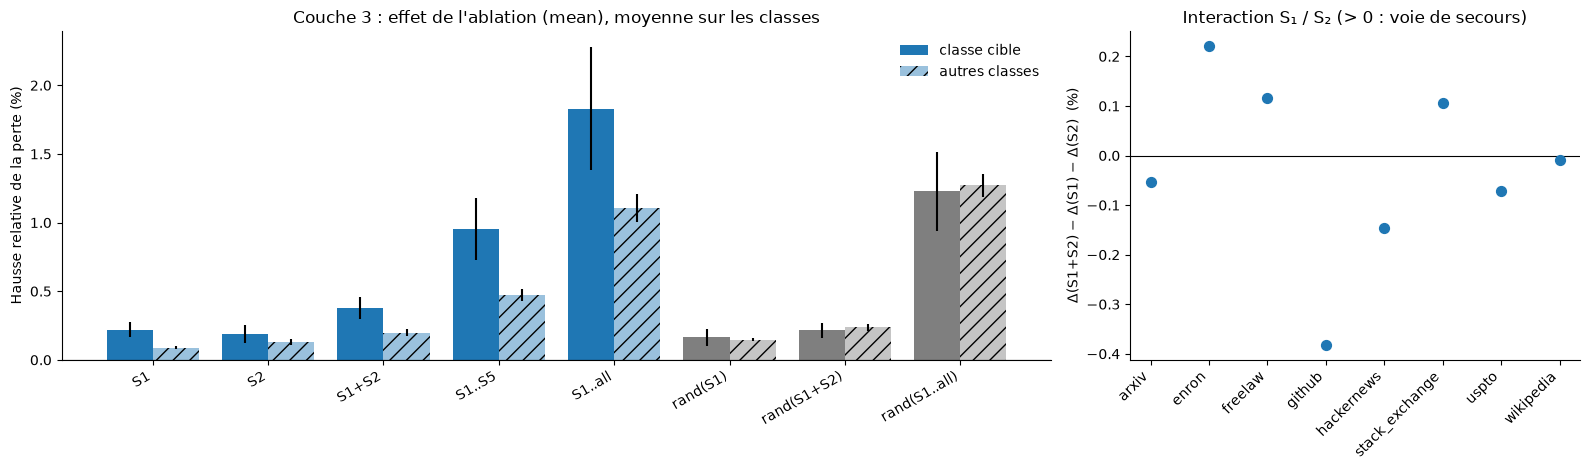

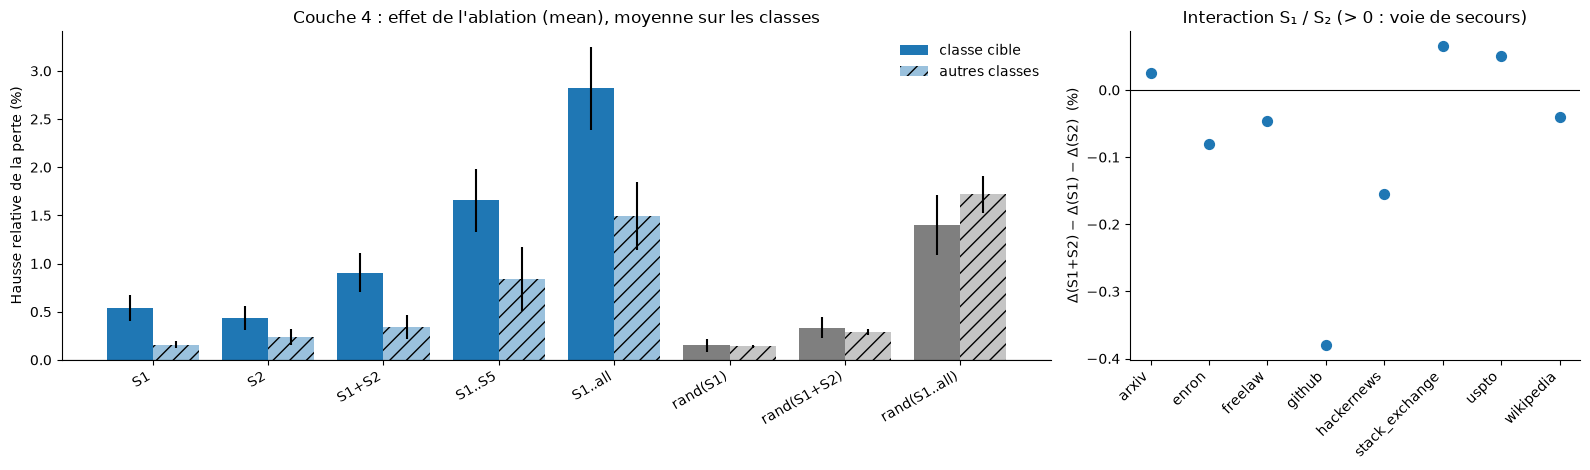

In [54]:
order_c = ["S1", "S2", "S1+S2", "S1..S5", "S1..all", "rand(S1)", "rand(S1+S2)", "rand(S1..all)"]
for l in ABL_LAYERS:
    sub = ablation[ablation.layer == l]
    g = sub.groupby("cond")[["d_target", "d_other"]].agg(["mean", "sem"]).reindex(order_c)
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
    x = np.arange(len(order_c))
    colors = ["tab:blue"] * 5 + ["tab:gray"] * 3
    axes[0].bar(x - 0.2, 100 * g[("d_target", "mean")], 0.4, yerr=100 * g[("d_target", "sem")],
                color=colors, label="classe cible")
    axes[0].bar(x + 0.2, 100 * g[("d_other", "mean")], 0.4, yerr=100 * g[("d_other", "sem")],
                color=colors, alpha=0.45, hatch="//", label="autres classes")
    axes[0].set_xticks(x, order_c, rotation=30, ha="right")
    axes[0].set_ylabel("Hausse relative de la perte (%)")
    axes[0].set_title(f"Couche {l} : effet de l'ablation ({ABLATION}), moyenne sur les classes")
    axes[0].axhline(0, color="black", lw=0.8)
    axes[0].legend(frameon=False)
    axes[0].spines[["top", "right"]].set_visible(False)

    it = piv.loc[l, "interaction"] * 100
    axes[1].scatter(range(len(it)), it.values, s=50, zorder=3)
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_xticks(range(len(it)), it.index, rotation=45, ha="right")
    axes[1].set_ylabel("Δ(S1+S2) − Δ(S1) − Δ(S2)  (%)")
    axes[1].set_title("Interaction S₁ / S₂ (> 0 : voie de secours)")
    axes[1].spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## Que codent les ordres supérieurs ?

On caractérise les neurones de chaque niveau sous deux angles.

**1. Profil entre classes (à partir des activations déjà extraites).** Pour chaque neurone sélectionné, on calcule sa taille d'effet d de Cohen pour **chaque** classe, et pas seulement pour la classe qui l'a sélectionné.
- **Sélectivité** : |d| pour la classe cible divisé par le |d| moyen pour les autres classes. Élevée : le neurone est propre à sa classe.
- **Étendue** : nombre de classes pour lesquelles |d| > 1. Élevée : le neurone réagit à plusieurs domaines.

Si les ordres supérieurs codent quelque chose de plus général, la sélectivité doit baisser et l'étendue augmenter avec le niveau. La heatmap montre, pour une classe et une couche, les d de chaque neurone (lignes, groupées par niveau) pour chaque classe (colonnes).

**2. Ce qui les active, token par token (passe avant du modèle).** On enregistre l'activation de chaque neurone sélectionné sur chaque token d'un échantillon de séquences. Pour un neurone et sa classe cible, on mesure de combien il s'active **plus** sur chaque type de token des textes de la classe que sur les autres textes (« excès »).
- **Concentration lexicale** : part de l'excès total portée par les 20 types de tokens qui y contribuent le plus. Élevée : le neurone détecte quelques marqueurs lexicaux précis (des mots-clés, des balises). Faible : il réagit à des indices diffus, répartis sur beaucoup de tokens (style, structure).
- **Top tokens** : pour quelques neurones de S₁ et des niveaux supérieurs, les tokens qui contribuent le plus à l'excès, pour une lecture qualitative.

**Hypothèse d'une hiérarchie de premier et second ordre** : S₁ concentré sur des marqueurs lexicaux spécifiques, les niveaux supérieurs plus diffus. L'hypothèse inverse, ou l'absence de tendance, est tout aussi informative.

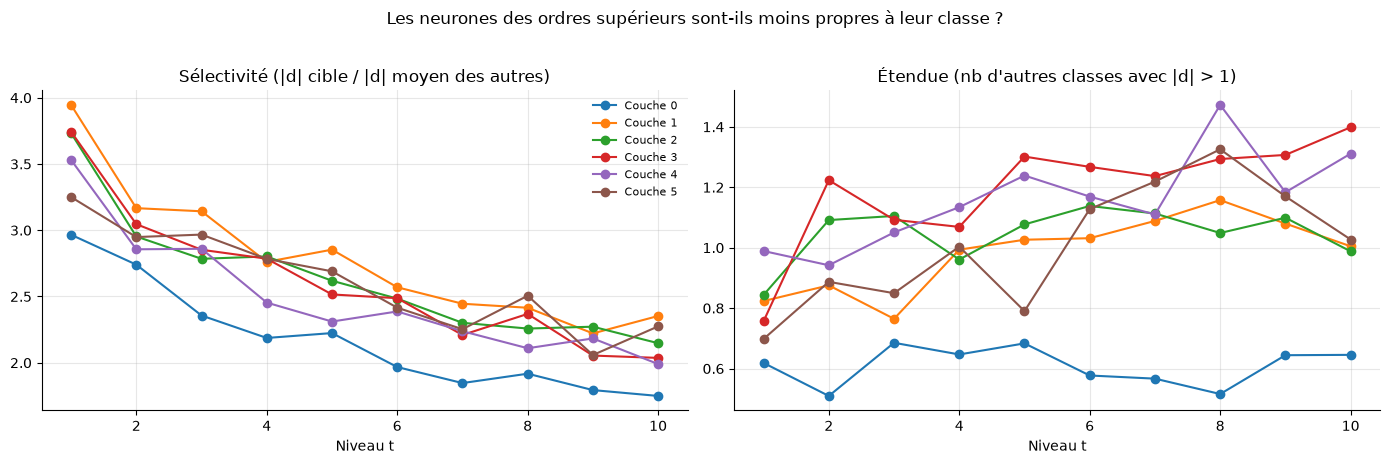

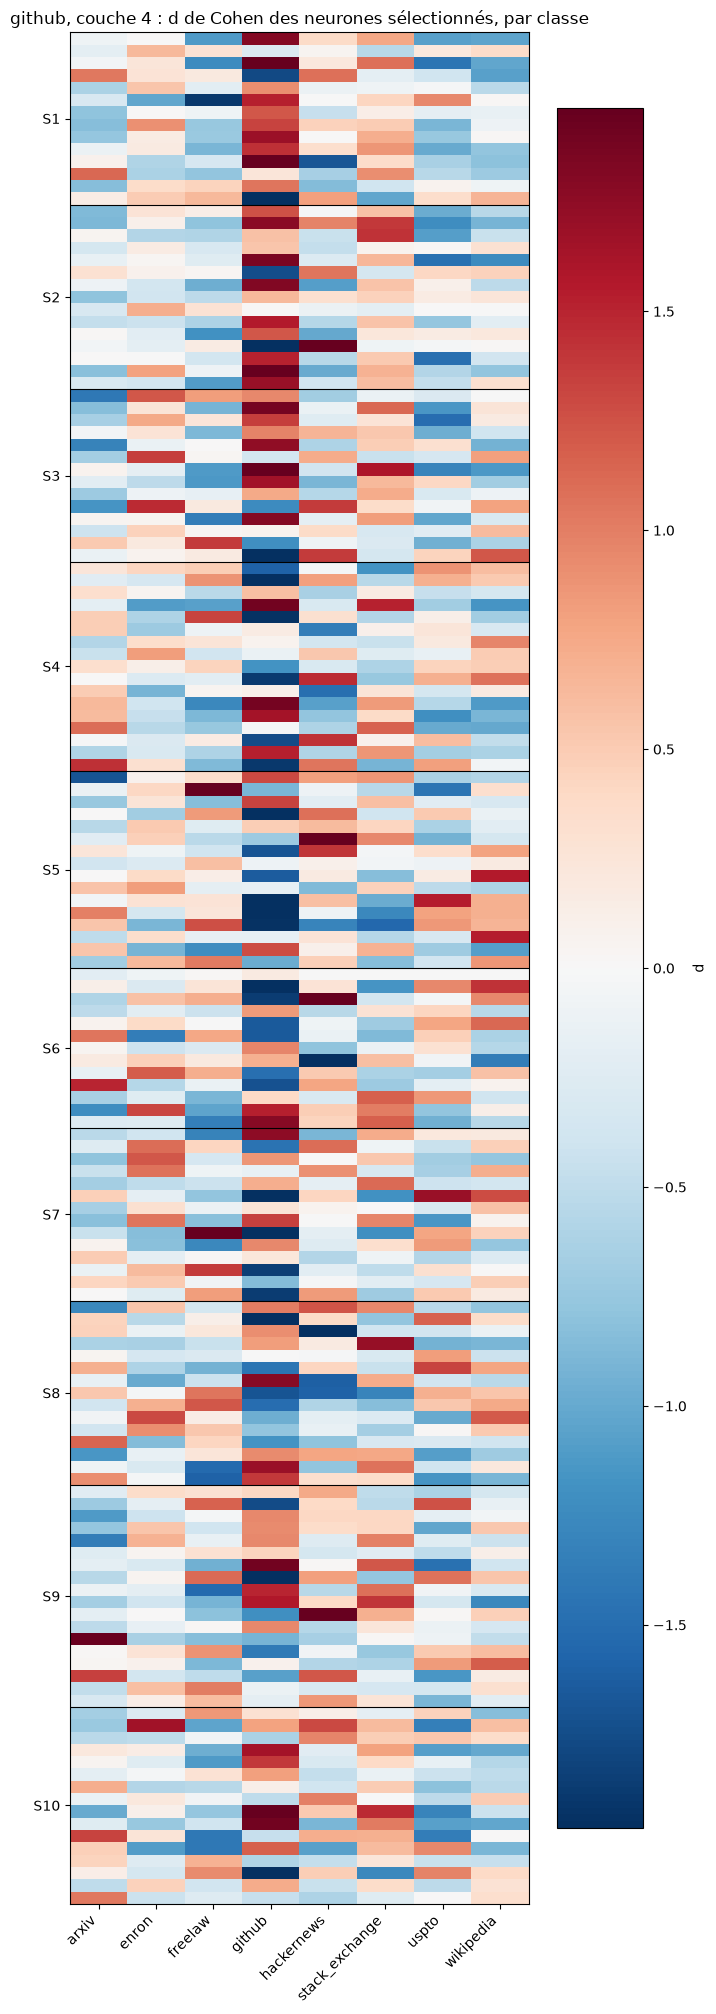

In [55]:
INT_LAYER = 4
INT_CLASS = "github"

# --- 1. Profil entre classes, toutes classes et couches
X_i = None
prof_rows, D_by_layer = [], {}
for l in layers:
    X_l = np.load(f"cached_activations/{MODEL}/{DS}/{l}.mean.npy").astype(np.float32)[idx_tr]
    X_l = (X_l - X_l.mean(0)) / np.maximum(X_l.std(0), 1e-3)
    Dl = np.stack([cohen_d(X_l, labels[idx_tr] == c) for c in classes])      # classes x neurones
    D_by_layer[l] = Dl
    for ci, c in enumerate(classes):
        for t, S in enumerate(R[(c, l)]["supports"], 1):
            S = np.asarray(S, int)
            ad = np.abs(Dl[:, S])
            others = np.delete(ad, ci, axis=0)
            prof_rows.append(dict(layer=l, cls=c, t=t,
                                  selectivity=np.median(ad[ci] / (others.mean(0) + 1e-6)),
                                  breadth=np.mean((others > 1).sum(0))))
profiles = pd.DataFrame(prof_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, title in [(axes[0], "selectivity", "Sélectivité (|d| cible / |d| moyen des autres)"),
                     (axes[1], "breadth", "Étendue (nb d'autres classes avec |d| > 1)")]:
    for l in layers:
        g = profiles[profiles.layer == l].groupby("t")[m].mean()
        ax.plot(g.index, g.values, marker="o", label=f"Couche {l}")
    ax.set_title(title); ax.set_xlabel("Niveau t")
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Les neurones des ordres supérieurs sont-ils moins propres à leur classe ?", y=1.02)
plt.tight_layout()
plt.show()

# Heatmap pour une classe et une couche : d de chaque neurone (lignes) pour chaque classe (colonnes)
sup = R[(INT_CLASS, INT_LAYER)]["supports"]
neur = np.concatenate([np.asarray(S, int) for S in sup])
lev = np.concatenate([[t] * len(S) for t, S in enumerate(sup, 1)])
H = D_by_layer[INT_LAYER][:, neur].T
lim = np.nanpercentile(np.abs(H), 98)
fig, ax = plt.subplots(figsize=(7, 0.12 * len(neur) + 2))
ax.imshow(H, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for t in range(1, len(sup)):
    ax.axhline(np.where(lev == t)[0][-1] + 0.5, color="black", lw=0.8)
ticks = [np.where(lev == t)[0].mean() for t in range(1, len(sup) + 1)]
ax.set_yticks(ticks, [f"S{t}" for t in range(1, len(sup) + 1)])
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
ax.set_title(f"{INT_CLASS}, couche {INT_LAYER} : d de Cohen des neurones sélectionnés, par classe")
plt.colorbar(ax.images[0], ax=ax, label="d")
plt.tight_layout()
plt.show()

81920 tokens, 913 neurones enregistrés en couche 4


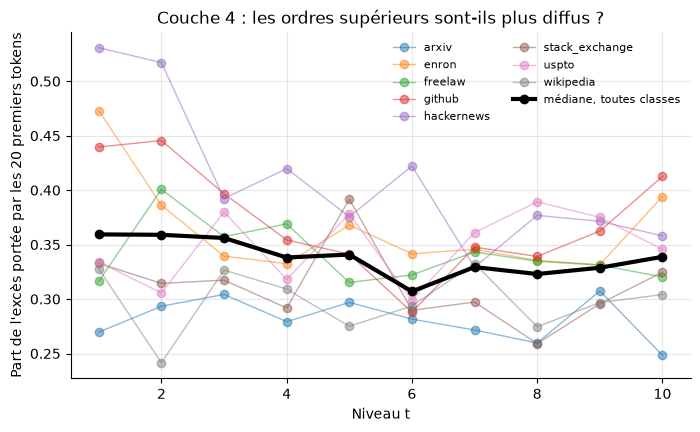

In [56]:
# --- 2. Activations token par token
N_TOK_SEQ = 20          # séquences par classe
TOP_K_TOKENS = 20

all_neur = np.unique(np.concatenate([np.asarray(S, int) for c in classes
                                     for S in R[(c, INT_LAYER)]["supports"]]))
tok_idx = np.concatenate([rng_abl.choice(idx_te[labels[idx_te] == c],
                                         min(N_TOK_SEQ, (labels[idx_te] == c).sum()), replace=False)
                          for c in classes])
captured = []
neur_t = torch.as_tensor(all_neur, device=device)


def capture(module, inp, out):
    captured.append(out[..., neur_t].float().cpu().numpy().astype(np.float16))


h = blocks[INT_LAYER].mlp.act.register_forward_hook(capture)
try:
    for s in range(0, len(tok_idx), BATCH):
        lm(TOKENS[tok_idx[s:s + BATCH]].to(device))
finally:
    h.remove()
ACT = np.concatenate(captured).reshape(-1, len(all_neur)).astype(np.float32)   # (tokens, neurones)
TOK_IDS = TOKENS[tok_idx].numpy().reshape(-1)
TOK_CLS = np.repeat(labels[tok_idx], TOKENS.shape[1])
col = {n: i for i, n in enumerate(all_neur)}
V = int(TOK_IDS.max()) + 1
print(f"{ACT.shape[0]} tokens, {ACT.shape[1]} neurones enregistrés en couche {INT_LAYER}")


def token_excess(neuron, c):
    """Excès d'activation par type de token, sur les textes de c, par rapport aux autres textes."""
    a = ACT[:, col[neuron]]
    tgt = TOK_CLS == c
    excess = a[tgt] - a[~tgt].mean()
    return np.bincount(TOK_IDS[tgt], weights=excess, minlength=V), np.bincount(TOK_IDS[tgt], minlength=V)


conc_rows = []
for c in classes:
    sign = np.sign(D_by_layer[INT_LAYER][classes.index(c)])
    for t, S in enumerate(R[(c, INT_LAYER)]["supports"], 1):
        for n in np.asarray(S, int):
            ex, _ = token_excess(n, c)
            ex = ex * sign[n]               # neurones qui s'éteignent pour c : on retourne le signe
            pos = np.clip(ex, 0, None)
            if pos.sum() <= 0:
                continue
            conc_rows.append(dict(cls=c, t=t, neuron=n,
                                  concentration=np.sort(pos)[::-1][:TOP_K_TOKENS].sum() / pos.sum()))
conc = pd.DataFrame(conc_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in classes:
    g = conc[conc.cls == c].groupby("t").concentration.median()
    ax.plot(g.index, g.values, marker="o", alpha=0.5, lw=1, label=c)
g = conc.groupby("t").concentration.median()
ax.plot(g.index, g.values, color="black", lw=3, marker="o", label="médiane, toutes classes")
ax.set_xlabel("Niveau t"); ax.set_ylabel(f"Part de l'excès portée par les {TOP_K_TOKENS} premiers tokens")
ax.set_title(f"Couche {INT_LAYER} : les ordres supérieurs sont-ils plus diffus ?")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [57]:
# --- Lecture qualitative : top tokens de quelques neurones par niveau
SHOW_LEVELS = [1, 2, 5, len(R[(INT_CLASS, INT_LAYER)]["supports"])]
N_NEURONS = 3
MIN_COUNT = 5

sign = np.sign(D_by_layer[INT_LAYER][classes.index(INT_CLASS)])
rows_top = []
for t in SHOW_LEVELS:
    S = np.asarray(R[(INT_CLASS, INT_LAYER)]["supports"][t - 1], int)
    S = S[np.argsort(-np.abs(D_by_layer[INT_LAYER][classes.index(INT_CLASS), S]))][:N_NEURONS]
    for n in S:
        ex, cnt = token_excess(n, INT_CLASS)
        ex = ex * sign[n]
        ex[cnt < MIN_COUNT] = -np.inf
        best = np.argsort(-ex)[:8]
        rows_top.append(dict(niveau=f"S{t}", neurone=int(n),
                             d=round(float(D_by_layer[INT_LAYER][classes.index(INT_CLASS), n]), 2),
                             top_tokens=" | ".join(repr(tok.decode([int(i)])) for i in best)))
pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(rows_top))

,niveau,neurone,d,top_tokens
0,S1,756,2.47,'.' | '_' | '/' | '\n' | ' ' | '[' | ' ' | '-'
1,S1,1602,2.31,"'\n' | ',' | ' ' | ' ' | '];' | ' {' | '(' | '/'"
2,S1,1940,-2.05,'.' | ' ' | ' ' | 'W' | ':' | '];' | '[' | ')'
3,S2,1879,2.15,"'\n' | '/' | '.' | '[' | ',' | '_' | '0' | ' '"
4,S2,1327,-2.03,'\n' | '_' | '[' | ' ' | '(' | '/' | '];' | ' '
5,S2,574,1.85,"'\n' | ' ' | '.' | ',' | ' ' | ':' | ';' | '];'"
6,S5,1438,-2.27,"'\n' | ' ' | '.' | ',' | '[' | '(' | '_' | ' '"
7,S5,1516,-2.20,"'\n' | '.' | ',' | ' ' | '/' | '[' | '(' | '_'"
8,S5,538,-1.97,'\n' | '.' | '[' | ' ' | '/' | '];' | ' ' | ';'
9,S10,1831,-2.34,'\n' | '.' | ' ' | '[' | '/' | '_' | '(' | '];'


### Lecture et précautions

- **Sélectivité et étendue** : si elles restent stables d'un niveau à l'autre, les ordres supérieurs codent la même chose que S₁, en plus faible (redondance). Si la sélectivité baisse et l'étendue augmente, ils codent des propriétés partagées entre domaines.
- **Concentration lexicale** : une baisse avec t indique que S₁ s'appuie sur des marqueurs lexicaux précis, et les ordres supérieurs sur des indices plus diffus. C'est la version qualitative d'une hiérarchie « premier ordre, second ordre ».
- **Top tokens** : à lire avec prudence, comme le rappellent Gurnee et al. (illusions d'interprétabilité) : un échantillon de `N_TOK_SEQ` séquences par classe ne montre que les comportements fréquents. Les neurones polysémantiques peuvent réagir à d'autres stimuli rares, absents de l'échantillon.
- **Effet de la force des neurones** : les neurones des niveaux supérieurs ont un |d| plus faible. Une partie des différences (sélectivité plus faible, concentration plus faible) peut venir de ce seul affaiblissement. Pour conclure, comparer à des neurones **non sélectionnés** de |d| comparable.